In [3]:
# CHURNGUARD AI
# MainCrafts SkillSprint
# Artificial Intelligence & Machine Learning
# Candidate: Your Name          <-- change this to your name

---
# 🗓️ DAY 1 — UNDERSTAND → PREPARE → BUILD
## STEP 2 — Understand the Problem

**Q1. What is customer churn?**
Churn is when a customer stops doing business with a company — cancels a subscription, switches to a competitor, or simply stops paying. In a telecom setting it means a subscriber who leaves the network. It is usually expressed as a churn rate: the share of customers lost in a period.

**Q2. Why would a company want to predict churn? (3+ reasons)**
1. **Acquiring is more expensive than retaining** – winning a new customer typically costs much more than keeping an existing one.
2. **Time to act** – a prediction gives the retention team a window to intervene (call, discount, plan review) *before* the customer has already decided to leave.
3. **Targeted spending** – retention budgets are limited; a risk score lets the company spend on the customers who are most likely to leave and most valuable to keep.
4. **Root-cause insight** – the features that drive the model (e.g. contract type, tenure) point to weaknesses in pricing, product or service.
5. **Revenue forecasting** – expected churn feeds directly into revenue and capacity planning.

**Q3. What is the target variable?**
The column **`Churn`** (`Yes` = the customer left, `No` = the customer stayed).

**Q4. Classification or regression?**
**Classification** (binary). The target is a category with two classes (churn / no churn), not a continuous number. The model outputs a class and also a probability of the "churn" class.

**Q5. What does a false negative mean here?**
A **false negative** = the model says *"customer will stay"* but the customer **actually leaves**. The company does nothing, and the customer — and all of their future revenue — is silently lost. A **false positive** = the model flags a customer who would have stayed anyway; the cost is only a wasted retention offer (e.g. an unnecessary discount). In most subscription businesses a lost customer costs far more than one wasted offer, so **false negatives are the more expensive mistake**, and *recall* on the churn class matters a lot.

## STEP 3 — Import Your Libraries

| Library | What it is used for in this project |
|---|---|
| **pandas** | Loading the CSV, inspecting, cleaning and grouping the customer table (DataFrames). |
| **numpy** | Fast numerical operations, arrays, conditional logic (`np.where`). |
| **matplotlib / seaborn** | Exploratory data analysis charts, confusion matrices and result plots. |
| **scikit-learn – `train_test_split`, `StratifiedKFold`** | Splitting data into train/test and cross-validation while keeping the churn ratio. |
| **scikit-learn – `OneHotEncoder`, `StandardScaler`, `ColumnTransformer`, `Pipeline`** | Converting text categories into numbers, scaling numeric columns, and chaining preprocessing + model so there is no data leakage. |
| **scikit-learn – `LogisticRegression`, `RandomForestClassifier`, `GradientBoostingClassifier`** | The classification models being compared. |
| **scikit-learn – `GridSearchCV`, `permutation_importance`** | Hyper-parameter tuning and measuring which features drive predictions. |
| **scikit-learn – metrics** | Accuracy, precision, recall, F1, ROC-AUC, confusion matrix, classification report. |
| **joblib** | Saving the trained model to disk so it can be reused without retraining. |

In [ ]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
)

RANDOM_STATE = 42
PALETTE = {"No": "#4C9F70", "Yes": "#D03549"}      # green = stayed, red = churned
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)
os.makedirs("models", exist_ok=True)

print("Libraries loaded successfully.")

ModuleNotFoundError: No module named 'numpy'

## STEP 4 — Load and Inspect the Dataset
The loader below searches a few common locations. In Google Colab, if the file is not found, it opens an upload dialog.

In [ ]:
DATASET_NAME = "Telco Customer Churn (IBM schema) - schema-identical replica"   # edit if you use another CSV

CANDIDATE_PATHS = ["customer_churn.csv", "dataset/customer_churn.csv", "../dataset/customer_churn.csv",
                   "/content/customer_churn.csv", "WA_Fn-UseC_-Telco-Customer-Churn.csv"]
data_path = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if data_path is None:
    try:                                             # Google Colab fallback
        from google.colab import files
        print("Dataset not found - please upload the churn CSV file.")
        uploaded = files.upload()
        data_path = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError("Place customer_churn.csv in the notebook folder or in dataset/.")

df = pd.read_csv(data_path)
print("Loaded from:", data_path)
print("Dataset shape:", df.shape)
display(df.head())

Loaded from: dataset/customer_churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,9774-KWRWK,Female,0,Yes,Yes,26,No,No phone service,DSL,No,Yes,No,No,Yes,No,Month-to-month,No,Electronic check,45.12,1163.93,Yes
1,4747-RIFIN,Male,1,Yes,No,33,Yes,Yes,DSL,No,No,Yes,No,Yes,Yes,Two year,Yes,Electronic check,74.17,2424.78,No
2,9019-EBASM,Female,1,No,Yes,14,Yes,No,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,108.00,1554.36,Yes
3,7340-WDOHS,Female,0,Yes,Yes,17,Yes,No,Fiber optic,No,No,No,Yes,No,Yes,Month-to-month,No,Bank transfer (automatic),92.36,1579.53,Yes
4,4663-QQAUO,Male,0,No,No,13,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,18.25,231.04,Yes


In [ ]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
display(df.describe(include="all"))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6965,2
top,9774-KWRWK,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3572,NaN,3786,5285,NaN,6314,3387,3060,3896,3680,3587,3942,3449,3347,3787,4159,2424,NaN,11,5060
mean,NaN,NaN,0.155616,NaN,NaN,30.488144,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63.926513,NaN,NaN
std,NaN,NaN,0.362516,NaN,NaN,19.365678,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.677220,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,14.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,43.180000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,28.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,66.730000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,46.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,87.520000,NaN,NaN


In [ ]:
# ---- What the task asks us to identify ----
target_col = "Churn"
raw_numeric = df.select_dtypes(include="number").columns.tolist()
raw_categorical = df.select_dtypes(exclude="number").columns.tolist()
n_rows, n_cols = df.shape
missing_raw = int(df.isnull().sum().sum())
dup_raw = int(df.duplicated().sum())

print(f"Number of rows            : {n_rows}")
print(f"Number of columns         : {n_cols}")
print(f"Numerical columns  ({len(raw_numeric)})  : {raw_numeric}")
print(f"Categorical columns({len(raw_categorical)}) : {raw_categorical}")
print(f"Missing values (NaN)      : {missing_raw}")
print(f"Duplicate records         : {dup_raw}")
print(f"Target column             : {target_col}  ->  {df[target_col].value_counts().to_dict()}")

Number of rows            : 7043
Number of columns         : 21
Numerical columns  (3)  : ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical columns(18) : ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']
Missing values (NaN)      : 0
Duplicate records         : 0
Target column             : Churn  ->  {'No': 5060, 'Yes': 1983}


**What we found.** The table has **7,043 customers and 21 columns**. There are no true `NaN` values and no duplicate rows, but there is a hidden problem: **`TotalCharges` is listed as text (`object`)** even though it should be a number — pandas could not read it as numeric because some cells contain a blank space `" "`. `customerID` is only an identifier (unique per row) and carries no predictive information. `SeniorCitizen` is stored as 0/1 but is really a yes/no category.

## STEP 5 — Data Cleaning
Typical issues to check: missing values, wrong data types, unnecessary identifiers, duplicate records, inconsistent categories.

In [ ]:
# 1) Wrong data type: TotalCharges is text because of blank strings -> convert to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values after conversion:")
print(df.isnull().sum()[lambda s: s > 0])

rows_missing = df[df["TotalCharges"].isnull()]
display(rows_missing[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
all_new_customers = bool((rows_missing["tenure"] == 0).all())
print("All rows with missing TotalCharges have tenure == 0:", all_new_customers)

Missing values after conversion:
TotalCharges    11
dtype: int64
All rows with missing TotalCharges have tenure == 0: True


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
1460,3095-FXRKE,0,101.94,NaN,Yes
2039,6874-CBETI,0,62.74,NaN,No
2134,5304-PSZUV,0,95.66,NaN,Yes
3397,5043-TITLC,0,41.75,NaN,No
3490,1964-JNTDO,0,81.75,NaN,No
4161,5394-SRPDG,0,71.83,NaN,Yes
4522,5128-GNGAG,0,48.80,NaN,Yes
5168,8227-GAEXN,0,52.50,NaN,No
5234,8211-DDMLW,0,18.38,NaN,Yes
6037,5720-ZRPWQ,0,101.65,NaN,Yes


**Decision – how missing values are handled (and why).**
The 11 rows with a missing `TotalCharges` **all have `tenure = 0`**: they are brand-new customers who have not been billed yet, so their lifetime total is genuinely **0**, not "unknown". Therefore the values are filled with **0** instead of deleting the rows (deleting would throw away real customers and would be a form of bias) or filling with the mean (which would invent a lifetime spend of ~₹1,953 for a customer who has paid nothing).

In [ ]:
# 2) Fill missing TotalCharges with 0 (new customers, nothing billed yet)
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# 3) Duplicate records (checked BEFORE dropping the ID, so identical rows are real duplicates)
dups = int(df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates removed:", dups)

# 4) Inconsistent categorical values: strip whitespace and inspect every category list
text_cols = df.select_dtypes(exclude="number").columns.drop("customerID")
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()
    print(f"{col:18s}: {sorted(df[col].unique())}")

# 5) Unnecessary identifier: customerID is unique per row and has no predictive meaning
df = df.drop(columns=["customerID"])

print("\nRemaining missing values:", int(df.isnull().sum().sum()))
print("Clean dataset shape:", df.shape)

Duplicates removed: 0
gender            : ['Female', 'Male']
Partner           : ['No', 'Yes']
Dependents        : ['No', 'Yes']
PhoneService      : ['No', 'Yes']
MultipleLines     : ['No', 'No phone service', 'Yes']
InternetService   : ['DSL', 'Fiber optic', 'No']
OnlineSecurity    : ['No', 'No internet service', 'Yes']
OnlineBackup      : ['No', 'No internet service', 'Yes']
DeviceProtection  : ['No', 'No internet service', 'Yes']
TechSupport       : ['No', 'No internet service', 'Yes']
StreamingTV       : ['No', 'No internet service', 'Yes']
StreamingMovies   : ['No', 'No internet service', 'Yes']
Contract          : ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  : ['No', 'Yes']
PaymentMethod     : ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn             : ['No', 'Yes']

Remaining missing values: 0
Clean dataset shape: (7043, 20)


**Notes on the categories.** The values `"No internet service"` and `"No phone service"` look like variants of `"No"`, but they are **kept as separate categories on purpose**: they tell the model that the customer has no internet/phone line at all, which is real information. All other categories are consistent (no spelling variants).

## STEP 6 — Explore the Data
Six visualisations, each followed by **"What does this tell us?"** written from the actual data.

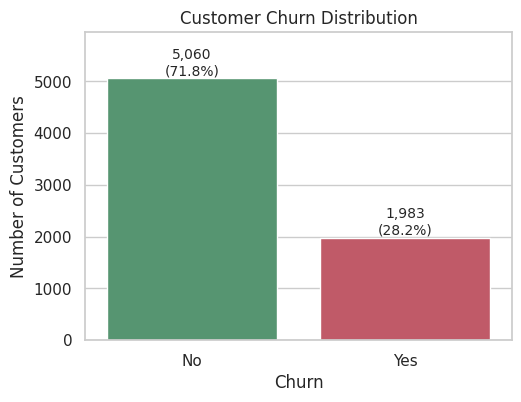

In [ ]:
churn_num = (df["Churn"] == "Yes").astype(int)
overall_churn_rate = churn_num.mean() * 100

def churn_rate_by(col):
    """Churn rate (%) for each category of `col`."""
    return (df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean()) * 100).sort_values(ascending=False)

# Visualization 1 - churn distribution
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], hue="Churn", palette=PALETTE, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}\n({p.get_height() / len(df):.1%})", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.savefig("images/01_churn_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**What does this tell us?** About **28.2%** of customers churned, so the classes are **imbalanced** (roughly 72 : 28). A model that always answers "No churn" would already be ~72% accurate while catching **zero** churners — so *accuracy alone is misleading* here and we must look at precision, recall and F1 for the churn class.

Contract
Month-to-month    45.9
One year          12.4
Two year           3.5


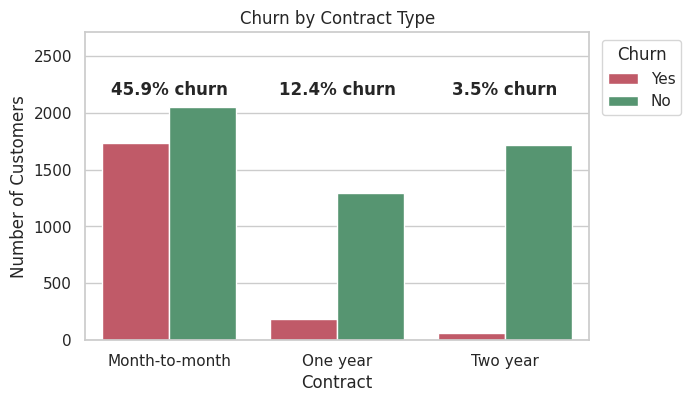

In [ ]:
# Visualization 2 - churn vs contract type
rate_contract = churn_rate_by("Contract")
order = ["Month-to-month", "One year", "Two year"]

fig, ax = plt.subplots(figsize=(6.5, 4))
sns.countplot(data=df, x="Contract", order=order, hue="Churn", palette=PALETTE, ax=ax)
ymax = max(p.get_height() for p in ax.patches)
ax.set_ylim(0, ymax * 1.32)
for i, c in enumerate(order):
    ax.text(i, ymax * 1.05, f"{rate_contract[c]:.1f}% churn", ha="center", fontweight="bold")
ax.legend(title="Churn", loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.title("Churn by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")
plt.savefig("images/02_churn_vs_contract.png", dpi=150, bbox_inches="tight")
plt.show()
print(rate_contract.round(1).to_string())

**What does this tell us?** Contract type is a very strong signal: **Month-to-month** customers churn at **45.9%**, while **Two year** customers churn at only **3.5%**. Customers with no long-term commitment can leave at any time, so this is likely one of the most important predictors.

Median tenure (months): {'No': 35.0, 'Yes': 15.0}


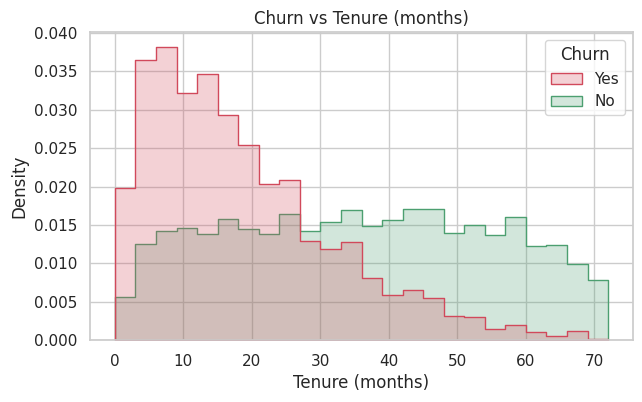

In [ ]:
# Visualization 3 - churn vs tenure
tenure_median = df.groupby("Churn")["tenure"].median()

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=24, stat="density", common_norm=False,
             palette=PALETTE, element="step", ax=ax)
plt.title("Churn vs Tenure (months)")
plt.xlabel("Tenure (months)")
plt.ylabel("Density")
plt.savefig("images/03_churn_vs_tenure.png", dpi=150, bbox_inches="tight")
plt.show()
print("Median tenure (months):", tenure_median.to_dict())

**What does this tell us?** Customers who churn are typically **newer**: median tenure is **15 months for churners vs 35 months for customers who stayed**. Churn risk is concentrated in the first year, which suggests the onboarding period is where retention effort should start.

Mean monthly charges: {'No': 58.8, 'Yes': 77.01}


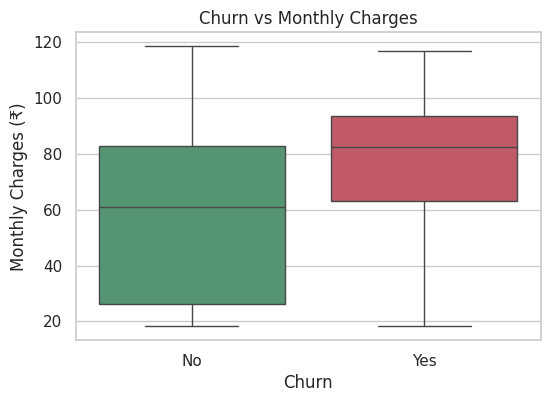

In [ ]:
# Visualization 4 - churn vs monthly charges
mc_mean = df.groupby("Churn")["MonthlyCharges"].mean()

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], hue="Churn", palette=PALETTE,
            legend=False, ax=ax)
plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges (₹)")
plt.savefig("images/04_churn_vs_monthly_charges.png", dpi=150, bbox_inches="tight")
plt.show()
print("Mean monthly charges:", mc_mean.round(2).to_dict())

**What does this tell us?** Churners pay more on average (**₹77.01** vs **₹58.80** per month). Higher bills may push customers to look for cheaper alternatives, especially when the bill is not backed by long-term contracts or support services. Monthly charges is informative but should be read together with contract and services.

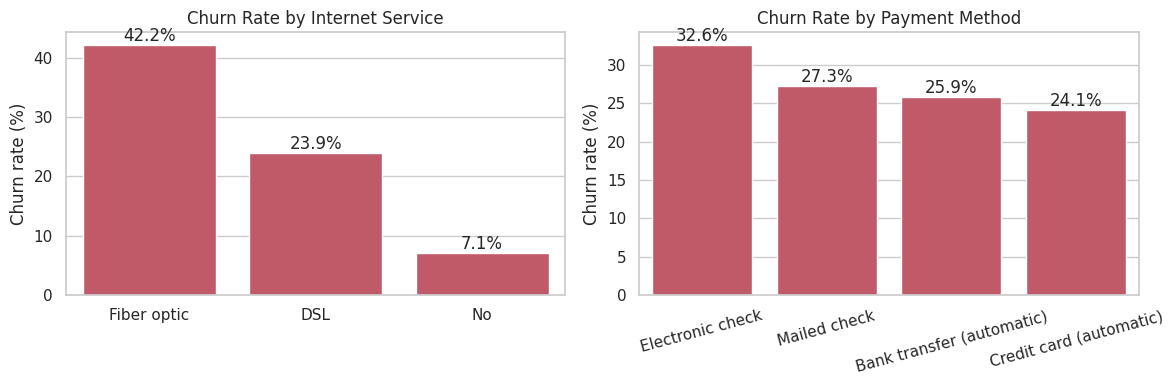

In [ ]:
# Visualization 5 - internet service & payment method
rate_internet = churn_rate_by("InternetService")
rate_payment = churn_rate_by("PaymentMethod")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=rate_internet.index, y=rate_internet.values, color="#D1495B", ax=axes[0])
axes[0].set_title("Churn Rate by Internet Service")
axes[0].set_ylabel("Churn rate (%)"); axes[0].set_xlabel("")
sns.barplot(x=rate_payment.index, y=rate_payment.values, color="#D1495B", ax=axes[1])
axes[1].set_title("Churn Rate by Payment Method")
axes[1].set_ylabel("Churn rate (%)"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=15)
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("images/05_churn_vs_internet_payment.png", dpi=150, bbox_inches="tight")
plt.show()

**What does this tell us?** By internet service, **Fiber optic** customers churn most (42.2%) and **No** least (7.1%). By payment method, **Electronic check** has the highest churn (32.6%) while **Credit card (automatic)** has the lowest (24.1%). Automatic payments look "stickier" than manual ones — a possible engagement/convenience effect.

tenure           -0.398
TotalCharges     -0.207
SeniorCitizen     0.022
MonthlyCharges    0.296


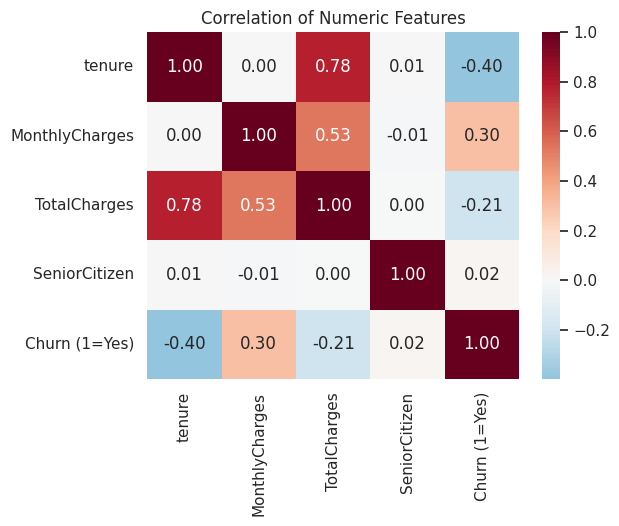

In [ ]:
# Visualization 6 - correlation of numeric columns with churn
corr_df = df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].copy()
corr_df["Churn (1=Yes)"] = churn_num
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
plt.title("Correlation of Numeric Features")
plt.savefig("images/06_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
corr_with_churn = corr["Churn (1=Yes)"].drop("Churn (1=Yes)").sort_values()
print(corr_with_churn.round(3).to_string())

**What does this tell us?** `tenure` has the strongest **negative** relationship with churn (r = -0.40): longer tenure → lower churn. `TotalCharges` is strongly correlated with `tenure` (r = 0.78) because it is roughly tenure × monthly charge, so the two carry overlapping information — this is fine for tree models and regularised logistic regression, but worth knowing when interpreting coefficients.

## STEP 7 — Prepare Features and Target

In [ ]:
X = df.drop("Churn", axis=1)
y = df["Churn"].map({"Yes": 1, "No": 0})          # 1 = churn, 0 = stay

numeric_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(exclude="number").columns   # text columns (object / string)

print("Numerical features:")
print(list(numeric_features))
print("\nCategorical features:")
print(list(categorical_features))
print("\nTarget balance:", y.value_counts(normalize=True).round(3).to_dict())

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target balance: {0: 0.718, 1: 0.282}


## STEP 8 — Split the Data
We keep 20% of the customers **hidden** from the model. `stratify=y` keeps the same churn ratio in both parts; `random_state=42` makes the split reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Churn share - train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Training samples: 5634
Testing samples: 1409
Churn share - train: 0.282 | test: 0.282


**Why not evaluate on the training data?** A model is judged by how well it works on customers it has **never seen**. On the training data it has already seen the answers, so a flexible model can simply memorise them and look almost perfect while failing on real new customers (**overfitting**). The untouched test set is our honest estimate of real-world performance — you will see this gap for the Random Forest in Step 11.

## STEP 9 — Build the Preprocessing Pipeline
Machine-learning models need numbers, so categorical text columns are converted by **OneHotEncoder** (one 0/1 column per category). `handle_unknown="ignore"` prevents a crash if a category appears at prediction time that was not seen in training. Numeric columns pass through unchanged for now. Putting the encoder inside a `Pipeline` means it is *fitted on training data only*, which prevents data leakage.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

## STEP 10 — Train Model #1: Logistic Regression
A simple, fast and interpretable linear model — a good baseline.

In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=1000))
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print(
    classification_report(
        y_test,
        logistic_predictions
    )
)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1012
           1       0.70      0.62      0.66       397

    accuracy                           0.82      1409
   macro avg       0.78      0.76      0.77      1409
weighted avg       0.81      0.82      0.82      1409



**Note on the `ConvergenceWarning` you may see above.** Logistic Regression uses an iterative optimiser and works best when numbers are on similar scales. Here `TotalCharges` is in the thousands while other columns are 0/1, so the optimiser may stop at its iteration limit. The predictions are still usable, and Day 2 fixes the cause properly with `StandardScaler`.

## STEP 11 — Train Model #2: Random Forest
An ensemble of many decision trees — captures non-linear patterns and interactions between features.

In [ ]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print(
    classification_report(
        y_test,
        rf_predictions
    )
)

# Why the test set matters: compare accuracy on data the model has seen vs unseen data
for name, mdl in [("Logistic Regression", logistic_model), ("Random Forest", rf_model)]:
    print(f"{name:20s} train accuracy = {mdl.score(X_train, y_train):.3f} | test accuracy = {mdl.score(X_test, y_test):.3f}")

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1012
           1       0.68      0.59      0.63       397

    accuracy                           0.81      1409
   macro avg       0.76      0.74      0.75      1409
weighted avg       0.80      0.81      0.80      1409

Logistic Regression  train accuracy = 0.814 | test accuracy = 0.819
Random Forest        train accuracy = 1.000 | test accuracy = 0.806


**Observation.** The Random Forest scores **100.0%** on the training data but only **80.6%** on unseen customers — it has memorised much of the training set. Logistic Regression is far more consistent (81.4% train vs 81.9% test). This is exactly why we judge models on the held-out test set.

## STEP 12 — Compare the Models

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, logistic_predictions),
        precision_score(y_test, rf_predictions)
    ],
    "Recall": [
        recall_score(y_test, logistic_predictions),
        recall_score(y_test, rf_predictions)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_predictions),
        f1_score(y_test, rf_predictions)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, rf_model.predict_proba(X_test)[:, 1])
    ]
})

display(results.round(3))

# Baseline winner on the churn class (used for the Day-1 demo and as the "Before" score on Day 2)
baseline_best_name = results.loc[results["F1 Score"].idxmax(), "Model"]
baseline_models = {"Logistic Regression": (logistic_model, logistic_predictions), "Random Forest": (rf_model, rf_predictions)}
baseline_best_model, baseline_best_predictions = baseline_models[baseline_best_name]
print("Best baseline by F1 (churn class):", baseline_best_name)

Best baseline by F1 (churn class): Logistic Regression


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.819,0.703,0.620,0.659,0.877
1,Random Forest,0.806,0.679,0.592,0.633,0.863


### Which metric matters most, and why?
**Recall (with F1 as a balance check)** — not accuracy.

* **Accuracy** hides the problem because only ~28% of customers churn. Both models look decent (~81%–82%) but accuracy rewards getting the majority class ("stay") right.
* **Recall** = "of all customers who really churned, how many did we catch?" Every missed churner (false negative) is a lost customer, which is the expensive mistake.
* **Precision** = "of the customers we flagged, how many really churned?" Low precision only means some retention offers are wasted.
* **F1** is the harmonic mean of precision and recall, so it stops us from "buying" recall by flagging everybody.

**Result:** the Random Forest has recall 59.2% and F1 0.633; Logistic Regression has recall 62.0% and F1 0.659. So on the churn class **Logistic Regression** is the stronger baseline, even though the accuracy difference between the two is small. The model is *not* chosen by accuracy alone.

## STEP 13 — Confusion Matrix

Best baseline (Logistic Regression):  TN=908  FP=104  FN=151  TP=246


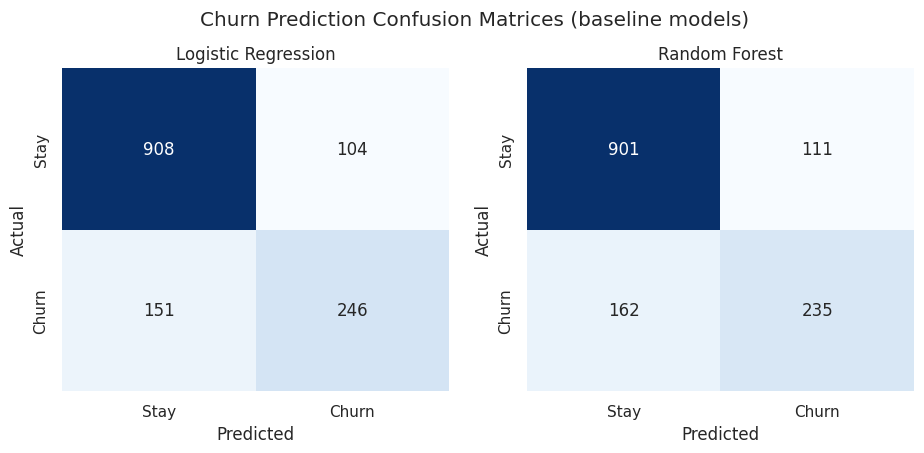

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, preds) in zip(axes, [("Logistic Regression", logistic_predictions), ("Random Forest", rf_predictions)]):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
    ax.set_title(f"{name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.suptitle("Churn Prediction Confusion Matrices (baseline models)", y=1.02)
plt.savefig("images/07_confusion_matrix_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, baseline_best_predictions).ravel()
print(f"Best baseline ({baseline_best_name}):  TN={tn}  FP={fp}  FN={fn}  TP={tp}")

**Explaining the four cells** (for Logistic Regression, test set of 1,409 customers):

| Cell | Meaning | Count |
|---|---|---|
| **True Positive (TP)** | Model said *churn* and the customer really churned — a customer we can try to save. | **246** |
| **True Negative (TN)** | Model said *stay* and the customer stayed — correctly left alone. | **908** |
| **False Positive (FP)** | Model said *churn* but the customer would have stayed — a wasted retention offer. | **104** |
| **False Negative (FN)** | Model said *stay* but the customer left — a silent loss, no chance to react. | **151** |

**Which error is more costly?** The **false negative**. As an illustration (assumed figures, not from the dataset): if a retention call/offer costs ₹500 but a lost customer is worth ₹15,000 in future revenue, one missed churner costs as much as **30 wasted offers**. That is why the business should tolerate some extra false positives in return for higher recall — and why Day 2 tests a class-weighted model.

## STEP 14 — Create a Customer Prediction Function
Users rarely know every one of the 19 input columns, so the function fills any field that is **not** provided with a typical value from the training data (most common category / median number). `TotalCharges` defaults to `tenure × MonthlyCharges`.

In [ ]:
BASE_COLUMNS = X.columns.tolist()
DEFAULTS = {c: X_train[c].mode()[0] for c in categorical_features}
DEFAULTS.update({c: float(X_train[c].median()) for c in numeric_features})

def build_customer_row(customer_data):
    """Turn a (partial) dict of customer info into a one-row DataFrame with every base column."""
    row = dict(DEFAULTS)
    row.update(customer_data)
    if "TotalCharges" not in customer_data:
        row["TotalCharges"] = row["tenure"] * row["MonthlyCharges"]
    return pd.DataFrame([row])[BASE_COLUMNS]

def predict_customer(customer_data, model):
    customer_df = build_customer_row(customer_data)

    prediction = model.predict(customer_df)[0]

    probability = model.predict_proba(
        customer_df
    )[0][1]

    if prediction == 1:
        risk = "HIGH"
        result = "Customer likely to churn"
    else:
        risk = "LOW"
        result = "Customer likely to stay"

    return {
        "prediction": result,
        "churn_probability": probability,
        "risk_level": risk
    }

sample_customer = {
    "Contract": "Month-to-month",
    "tenure": 5,
    "MonthlyCharges": 79.50,
    "InternetService": "Fiber optic",
}

out = predict_customer(sample_customer, baseline_best_model)

print("Customer Churn Prediction")
print("-------------------------")
print("Contract:", sample_customer["Contract"])
print("Tenure:", sample_customer["tenure"], "months")
print(f"Monthly Charges: ₹{sample_customer['MonthlyCharges']:.2f}")
print("Internet Service:", sample_customer["InternetService"])
print()
print("Predicted Churn:", "YES" if out["risk_level"] == "HIGH" else "NO")
print(f"Churn Probability: {out['churn_probability']:.1%}")
print("Risk Level:", out["risk_level"])

Customer Churn Prediction
-------------------------
Contract: Month-to-month
Tenure: 5 months
Monthly Charges: ₹79.50
Internet Service: Fiber optic

Predicted Churn: YES
Churn Probability: 86.0%
Risk Level: HIGH


## STEP 15 — Business Interpretation (baseline model)

**Model Performance.** The best baseline (Logistic Regression) achieved an **F1-score of 0.659** for the churn class, with recall of 62.0% and precision of 70.3%. Accuracy alone (81.9%) would overstate how well churners are found.

**Business Interpretation.** The model can help the company identify customers who show characteristics associated with churn (short tenure, month-to-month contract, fibre internet, electronic-check payment).

**Possible Action.** Customers flagged as higher-risk can be considered for retention campaigns, service reviews or targeted offers.

**Limitation.** Model predictions are not guarantees that an individual customer will churn — about 30% of flagged customers would not have left. **ML prediction ≠ certainty.**

---
# 🗓️ DAY 2 — IMPROVE → TEST → DOCUMENT → PRESENT
## Challenge A — Improve Your Model
Baseline results on Day 1 are the starting point. Improvements tested here:

1. **Feature engineering** – six new columns built from existing ones (`num_addons`, `protection_services`, `avg_monthly_spend`, `charge_vs_avg`, `tenure_group`, `has_family`).
2. **Better preprocessing** – scaling numeric columns for the linear model.
3. **Handling class imbalance** – `class_weight` so churners count more during training.
4. **Hyper-parameter tuning** – `GridSearchCV` on the Random Forest.
5. **Comparing another algorithm** – Gradient Boosting.

**Fair model selection.** To avoid "peeking" at the test set, candidates are ranked by **5-fold cross-validated F1 on the training data only**. The test set is used just to *report* results.

In [25]:
ADDON_COLS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def engineer_features(data):
    """Row-wise feature engineering (no statistics learned from data -> no leakage)."""
    d = data.copy()
    d["num_addons"] = (d[ADDON_COLS] == "Yes").sum(axis=1)                       # how many add-on services
    d["protection_services"] = (d[["OnlineSecurity", "TechSupport"]] == "Yes").sum(axis=1)   # security + support
    avg = d["TotalCharges"] / d["tenure"].clip(lower=1)
    d["avg_monthly_spend"] = np.where(d["tenure"] > 0, avg, d["MonthlyCharges"])   # historical average bill
    d["charge_vs_avg"] = d["MonthlyCharges"] - d["avg_monthly_spend"]              # >0 => bill rose vs history
    d["tenure_group"] = pd.cut(d["tenure"], bins=[-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]).astype(str)
    d["has_family"] = np.where((d["Partner"] == "Yes") | (d["Dependents"] == "Yes"), "Yes", "No")
    return d

X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)
new_features = [c for c in X_train_fe.columns if c not in X_train.columns]
print("New features:", new_features)
display(X_train_fe[new_features].head())

def make_preprocessor(X_ref, scale=True):
    num = X_ref.select_dtypes(include="number").columns
    cat = X_ref.select_dtypes(exclude="number").columns
    parts = [("categorical", OneHotEncoder(handle_unknown="ignore"), cat)]
    if scale:
        parts.append(("numeric", StandardScaler(), num))
    return ColumnTransformer(parts)

New features: ['num_addons', 'protection_services', 'avg_monthly_spend', 'charge_vs_avg', 'tenure_group', 'has_family']


,num_addons,protection_services,avg_monthly_spend,charge_vs_avg,tenure_group,has_family
3959,3,0,82.580000,-0.050000,0-12,Yes
4018,1,0,85.686667,-0.386667,13-24,Yes
3973,0,0,25.612979,0.487021,25-48,No
5385,0,0,20.856667,0.043333,25-48,No
5813,2,0,95.450588,1.049412,13-24,Yes


In [26]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate(model, X_eval):
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]
    return {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "F1 Score": f1_score(y_test, pred),
            "ROC-AUC": roc_auc_score(y_test, proba)}

def cv_f1(model, X_tr):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")            # baseline LR may emit ConvergenceWarning (explained in Step 10)
        return cross_val_score(model, X_tr, y_train, cv=skf, scoring="f1", n_jobs=1).mean()

experiments = {}     # name -> (fitted model, test features, CV-F1)

# Baselines from Day 1 (original 19 features)
experiments["1. Logistic Regression (baseline)"] = (logistic_model, X_test, cv_f1(logistic_model, X_train))
experiments["2. Random Forest (baseline)"] = (rf_model, X_test, cv_f1(rf_model, X_train))

# 3. Logistic Regression + new features + scaling
m3 = Pipeline([("preprocessor", make_preprocessor(X_train_fe, scale=True)),
               ("model", LogisticRegression(max_iter=2000))]).fit(X_train_fe, y_train)
experiments["3. Logistic Reg. + features + scaling"] = (m3, X_test_fe, cv_f1(m3, X_train_fe))

# 4. ... + class_weight="balanced" (handling class imbalance)
m4 = Pipeline([("preprocessor", make_preprocessor(X_train_fe, scale=True)),
               ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(X_train_fe, y_train)
experiments["4. Logistic Reg. + features + class weight"] = (m4, X_test_fe, cv_f1(m4, X_train_fe))

# 5. Another algorithm: Gradient Boosting
m5 = Pipeline([("preprocessor", make_preprocessor(X_train_fe, scale=False)),
               ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))]).fit(X_train_fe, y_train)
experiments["5. Gradient Boosting + features"] = (m5, X_test_fe, cv_f1(m5, X_train_fe))

print("Trained", len(experiments), "candidates so far.")

Trained 5 candidates so far.


In [27]:
# 6. Random Forest + features + class weight, tuned with GridSearchCV (optimises F1 on the training folds)
rf_tuned_pipe = Pipeline([
    ("preprocessor", make_preprocessor(X_train_fe, scale=False)),
    ("model", RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)),
])
param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [6, 10, None],
    "model__min_samples_leaf": [3, 8, 15],
}
grid = GridSearchCV(rf_tuned_pipe, param_grid, scoring="f1", cv=skf, n_jobs=-1)
grid.fit(X_train_fe, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1     : %.3f" % grid.best_score_)
experiments["6. Random Forest + features + class weight (tuned)"] = (grid.best_estimator_, X_test_fe, grid.best_score_)

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 8, 'model__n_estimators': 200}
Best CV F1     : 0.671



Selected model: 4. Logistic Reg. + features + class weight


,Experiment,CV F1 (train),Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,1. Logistic Regression (baseline),0.647,0.819,0.703,0.620,0.659,0.877
1,2. Random Forest (baseline),0.603,0.806,0.679,0.592,0.633,0.863
2,3. Logistic Reg. + features + scaling,0.648,0.819,0.706,0.612,0.656,0.877
3,4. Logistic Reg. + features + class weight,0.674,0.790,0.595,0.793,0.680,0.877
4,5. Gradient Boosting + features,0.632,0.814,0.699,0.597,0.644,0.871
5,6. Random Forest + features + class weight (tuned),0.671,0.791,0.600,0.781,0.678,0.869


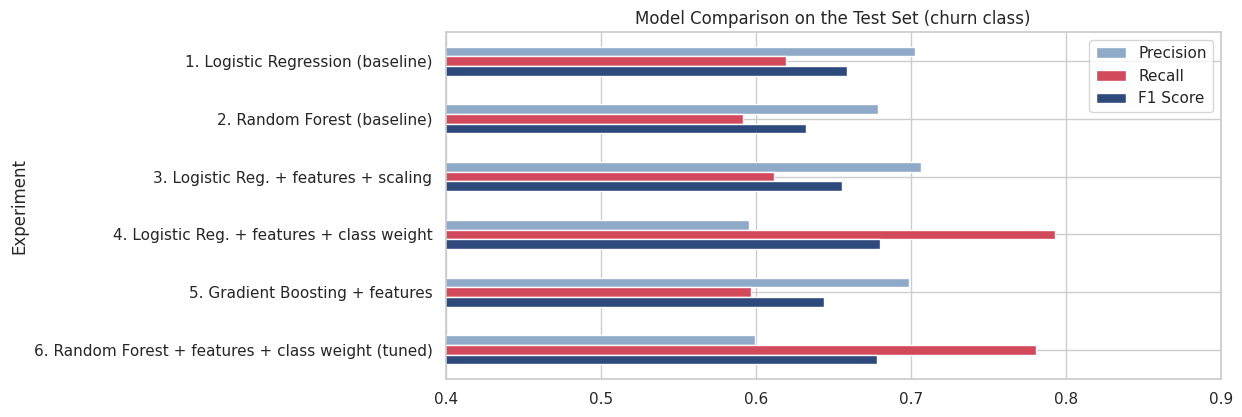

In [28]:
rows = []
for name, (mdl, X_eval, cvscore) in experiments.items():
    rows.append({"Experiment": name, "CV F1 (train)": cvscore, **evaluate(mdl, X_eval)})
experiment_table = pd.DataFrame(rows)
display(experiment_table.round(3))

# ---- Model selection: highest cross-validated F1 (training data only) ----
final_name = experiment_table.loc[experiment_table["CV F1 (train)"].idxmax(), "Experiment"]
final_model, X_test_final, _ = experiments[final_name]
final_metrics = evaluate(final_model, X_test_final)
print("\nSelected model:", final_name)

# Bar chart of test F1 / recall for every experiment
fig, ax = plt.subplots(figsize=(10, 4.5))
plot_df = experiment_table.set_index("Experiment")[["Precision", "Recall", "F1 Score"]]
plot_df.plot(kind="barh", ax=ax, color=["#8FA9C9", "#D1495B", "#2E4A7D"])
ax.set_xlim(0.4, 0.9)
ax.set_title("Model Comparison on the Test Set (churn class)")
ax.invert_yaxis()
plt.savefig("images/08_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [29]:
# ---- BEFORE vs AFTER ----
before_row = experiment_table[experiment_table["Experiment"].str.contains("baseline")].sort_values("F1 Score", ascending=False).iloc[0]
before_f1, before_recall = before_row["F1 Score"], before_row["Recall"]
after_f1, after_recall = final_metrics["F1 Score"], final_metrics["Recall"]

print(f"Before  ({before_row['Experiment']})")
print(f"   F1 Score = {before_f1:.3f} | Recall = {before_recall:.3f} | Precision = {before_row['Precision']:.3f}")
print(f"After   ({final_name})")
print(f"   F1 Score = {after_f1:.3f} | Recall = {after_recall:.3f} | Precision = {final_metrics['Precision']:.3f}")

Before  (1. Logistic Regression (baseline))
   F1 Score = 0.659 | Recall = 0.620 | Precision = 0.703
After   (4. Logistic Reg. + features + class weight)
   F1 Score = 0.680 | Recall = 0.793 | Precision = 0.595


### Documenting the improvement

**Before** — F1 Score = **0.659** (recall 0.620) · *1. Logistic Regression (baseline)*
**After** — F1 Score = **0.680** (recall 0.793) · *4. Logistic Reg. + features + class weight*

**What changed? (step by step, test-set F1)**
Baseline **0.659** → + engineered features & scaling **0.656** → + class weighting **0.680**. Engineered features (`num_addons, protection_services, avg_monthly_spend, charge_vs_avg, tenure_group, has_family`) and scaling on their own had a negligible effect on F1 (-0.003). Adding **class weighting** moved recall from 0.612 to 0.793 and F1 to 0.680. Gradient Boosting reached F1 0.644 and the tuned, class-weighted Random Forest 0.678. Overall, F1 increased by 0.022 and recall increased by 0.174; the selected pipeline is **Logistic Reg. + features + class weight**.

**Why did we make the change?**
* The original models leave many churners undetected (recall only 62%) because churners are a minority class and the model is rewarded for predicting "stay". **Class weighting** tells the model that missing a churner is more costly, which is exactly the business requirement from Q5.
* **Engineered features and scaling** were tested because they summarise behaviour (number of services, bill vs history, tenure bands) and remove the optimiser warning. Whatever their effect turns out to be, documenting it honestly is part of the experiment.
* **Cross-validated F1 for selection** protects against choosing a model that just happens to fit the test set.

Trade-off to be aware of: pushing recall up normally lowers precision — more customers are flagged, and some of them would have stayed. The business has to decide how many extra retention offers it is willing to pay for to catch more real churners.

### Final model evaluation

              precision    recall  f1-score   support

        Stay       0.91      0.79      0.84      1012
       Churn       0.60      0.79      0.68       397

    accuracy                           0.79      1409
   macro avg       0.75      0.79      0.76      1409
weighted avg       0.82      0.79      0.80      1409

TN=798  FP=214  FN=82  TP=315


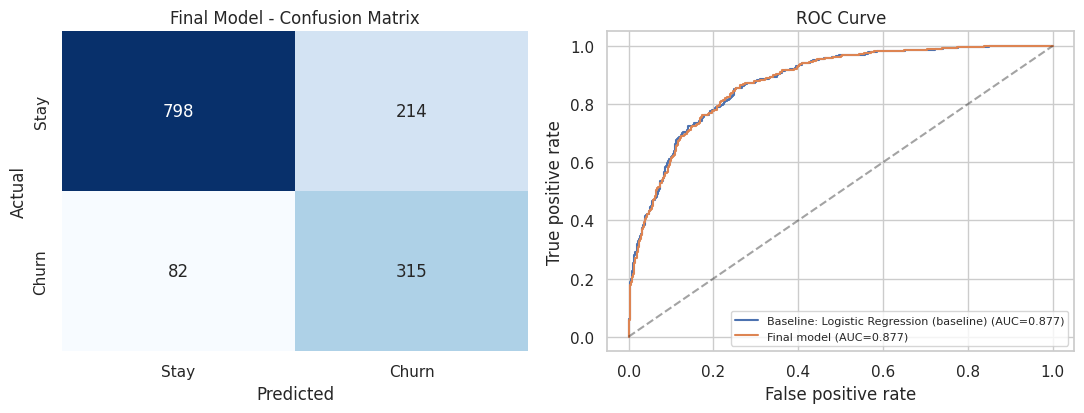

In [30]:
final_pred = final_model.predict(X_test_final)
final_proba = final_model.predict_proba(X_test_final)[:, 1]
print(classification_report(y_test, final_pred, target_names=["Stay", "Churn"]))

cm = confusion_matrix(y_test, final_pred)
tn_f, fp_f, fn_f, tp_f = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"])
axes[0].set_title("Final Model - Confusion Matrix")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

for label, mdl, Xe in [("Baseline: " + before_row["Experiment"].split(". ")[1], experiments[before_row["Experiment"]][0], experiments[before_row["Experiment"]][1]),
                       ("Final model", final_model, X_test_final)]:
    fpr, tpr, _ = roc_curve(y_test, mdl.predict_proba(Xe)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{label} (AUC={roc_auc_score(y_test, mdl.predict_proba(Xe)[:, 1]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[1].set_title("ROC Curve"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("images/09_final_confusion_matrix_roc.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"TN={tn_f}  FP={fp_f}  FN={fn_f}  TP={tp_f}")

**Reading the final matrix.** Out of 397 customers who really churned, the model catches **315** (recall 79.3%) and misses **82**. It raises **214** false alarms among 1012 customers who stayed. The ROC-AUC of **0.877** means that a randomly picked churner receives a higher churn probability than a randomly picked stayer about 88% of the time.

### Which features influence predictions? (feature importance)
**Permutation importance** shuffles one original column at a time on the test set and measures how much the F1-score drops. It works for any model type and reports importance per *original* column (not per one-hot dummy), which is easier to explain to a business audience.

,importance
Contract,0.1491
tenure,0.0669
InternetService,0.0229
PaymentMethod,0.0086
tenure_group,0.0043
protection_services,0.0034
gender,0.0014
TotalCharges,0.0007
OnlineSecurity,0.0004
has_family,0.0003


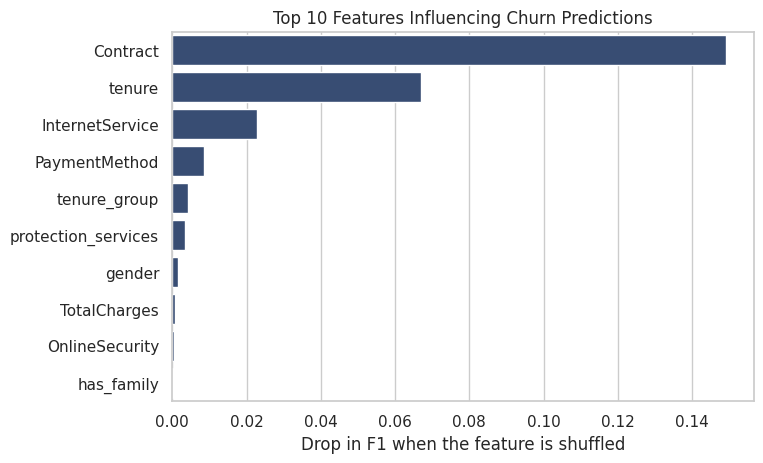

In [31]:
perm = permutation_importance(final_model, X_test_final, y_test, scoring="f1", n_repeats=5,
                              random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.Series(perm.importances_mean, index=X_test_final.columns)
              .sort_values(ascending=False))
top_features = importance.head(10)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.barplot(x=top_features.values, y=top_features.index, color="#2E4A7D", ax=ax)
ax.set_title("Top 10 Features Influencing Churn Predictions")
ax.set_xlabel("Drop in F1 when the feature is shuffled")
ax.set_ylabel("")
plt.savefig("images/10_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
display(top_features.round(4).to_frame("importance"))

**Interpretation.** The most influential features are **Contract, tenure, InternetService**, followed by PaymentMethod, tenure_group, protection_services. This agrees with the exploratory analysis: contract type, tenure and the kind of service/payment the customer has are the levers that separate leavers from stayers. Note that importance shows *what the model relies on*, not *why customers leave* — it is association, not proof of cause.

## Challenge B — Build a Risk Output
The probability is converted into **three risk levels**. The thresholds are a *business choice*, not a universal truth — so below they are justified using the real churn rate observed inside each band on the test set.

Bands correctly ordered (HIGH > MEDIUM > LOW churn rate): True


,Customers,Share of customers (%),Actual churn rate (%),Churners captured (%)
HIGH,414,29.4,66.9,69.8
MEDIUM,205,14.5,33.2,17.1
LOW,790,56.1,6.6,13.1


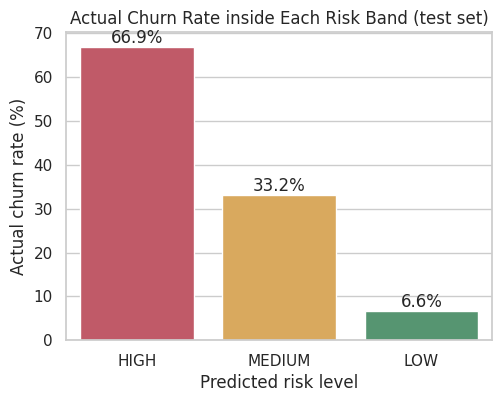

In [32]:
HIGH_T, MEDIUM_T = 0.65, 0.40

DECISION_THRESHOLD = 0.50     # "Predicted Churn: YES" uses the same 0.5 rule as the evaluated model

def risk_level(probability):
    if probability >= HIGH_T:
        return "HIGH"
    elif probability >= MEDIUM_T:
        return "MEDIUM"
    else:
        return "LOW"

ACTIONS = {
    "HIGH": "Priority retention: personal call / targeted offer / move to a longer contract.",
    "MEDIUM": "Monitor and nudge: service check-in, add-on trial, loyalty communication.",
    "LOW": "No action needed: routine engagement only.",
}

bands = pd.Series([risk_level(p) for p in final_proba], index=y_test.index)
band_table = pd.DataFrame({
    "Customers": bands.value_counts(),
    "Share of customers (%)": bands.value_counts(normalize=True) * 100,
    "Actual churn rate (%)": y_test.groupby(bands).mean() * 100,
    "Churners captured (%)": y_test.groupby(bands).sum() / y_test.sum() * 100,
}).reindex(["HIGH", "MEDIUM", "LOW"])
display(band_table.round(1))
bands_ordered = bool(band_table.loc["HIGH", "Actual churn rate (%)"] > band_table.loc["MEDIUM", "Actual churn rate (%)"] > band_table.loc["LOW", "Actual churn rate (%)"])
print("Bands correctly ordered (HIGH > MEDIUM > LOW churn rate):", bands_ordered)

fig, ax = plt.subplots(figsize=(5.5, 4))
sns.barplot(x=band_table.index, y=band_table["Actual churn rate (%)"], hue=band_table.index,
            palette={"HIGH": "#D1495B", "MEDIUM": "#EDAE49", "LOW": "#4C9F70"}, legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
ax.set_title("Actual Churn Rate inside Each Risk Band (test set)")
ax.set_ylabel("Actual churn rate (%)"); ax.set_xlabel("Predicted risk level")
plt.savefig("images/11_risk_bands.png", dpi=150, bbox_inches="tight")
plt.show()

**Why these thresholds?** Because the final model uses class weighting, its probabilities are pushed upwards for churners (they are not calibrated frequencies), so the cut-offs were chosen by looking at how the **actual churn rate behaves inside each band**:

* **HIGH (probability ≥ 0.65)** – 29.4% of customers, of whom **66.9%** really churned; this band alone contains **69.8%** of all churners → worth a costly, personal intervention.
* **MEDIUM (0.40 – 0.65)** – 14.5% of customers with a **33.2%** churn rate → cheap, automated nudges.
* **LOW (< 0.40)** – 56.1% of customers with only **6.6%** churn → leave alone.

The bands are ordered as they should be (HIGH > MEDIUM > LOW), which is the sanity check that the score is useful. A company with a small retention budget would raise the HIGH threshold; one with a cheap automated offer could lower it.

In [33]:
def predict_churn(customer_data, model=None):
    """Full pipeline for a NEW customer: fill defaults -> engineer features -> probability -> risk level."""
    model = model or final_model
    row = engineer_features(build_customer_row(customer_data))
    probability = float(model.predict_proba(row)[0, 1])
    level = risk_level(probability)
    return {"predicted_churn": "YES" if probability >= DECISION_THRESHOLD else "NO", "churn_probability": probability,
            "risk_level": level, "suggested_action": ACTIONS[level]}

def show_prediction(title, customer_data):
    r = predict_churn(customer_data)
    print("Customer Churn Prediction  -", title)
    print("-" * 50)
    for k, v in customer_data.items():
        print(f"{k:16s}: {'₹' + format(v, '.2f') if k == 'MonthlyCharges' else v}")
    print(f"\nPredicted Churn : {r['predicted_churn']}")
    print(f"Churn Probability: {r['churn_probability']:.1%}")
    print(f"Risk Level      : {r['risk_level']}")
    print(f"Suggested Action: {r['suggested_action']}\n")
    return r

demo_customers = {
    "New fibre customer on a monthly plan": {"Contract": "Month-to-month", "tenure": 5, "MonthlyCharges": 79.50,
        "InternetService": "Fiber optic", "PaymentMethod": "Electronic check", "OnlineSecurity": "No", "TechSupport": "No"},
    "Mid-tenure customer on a one-year plan": {"Contract": "One year", "tenure": 30, "MonthlyCharges": 65.00,
        "InternetService": "DSL", "PaymentMethod": "Mailed check"},
    "Loyal customer on a two-year plan": {"Contract": "Two year", "tenure": 60, "MonthlyCharges": 55.00,
        "InternetService": "DSL", "PaymentMethod": "Bank transfer (automatic)", "OnlineSecurity": "Yes", "TechSupport": "Yes"},
}
demo_predictions = {name: show_prediction(name, c) for name, c in demo_customers.items()}

Customer Churn Prediction  - New fibre customer on a monthly plan
--------------------------------------------------
Contract        : Month-to-month
tenure          : 5
MonthlyCharges  : ₹79.50
InternetService : Fiber optic
PaymentMethod   : Electronic check
OnlineSecurity  : No
TechSupport     : No

Predicted Churn : YES
Churn Probability: 93.3%
Risk Level      : HIGH
Suggested Action: Priority retention: personal call / targeted offer / move to a longer contract.

Customer Churn Prediction  - Mid-tenure customer on a one-year plan
--------------------------------------------------
Contract        : One year
tenure          : 30
MonthlyCharges  : ₹65.00
InternetService : DSL
PaymentMethod   : Mailed check

Predicted Churn : NO
Churn Probability: 19.2%
Risk Level      : LOW
Suggested Action: No action needed: routine engagement only.

Customer Churn Prediction  - Loyal customer on a two-year plan
--------------------------------------------------
Contract        : Two year
tenure     

In [34]:
# ---- Save the trained model + metadata, then reload it to prove it works ----
joblib.dump(final_model, "models/churnguard_model.joblib")
metadata = {
    "selected_model": final_name,
    "high_threshold": HIGH_T, "medium_threshold": MEDIUM_T,
    "base_columns": BASE_COLUMNS,
    "defaults": {k: (v if isinstance(v, str) else float(v)) for k, v in DEFAULTS.items()},
    "categorical_options": {c: sorted(X[c].unique().tolist()) for c in categorical_features},
}
with open("models/churnguard_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

loaded_model = joblib.load("models/churnguard_model.joblib")
test_customer = demo_customers["New fibre customer on a monthly plan"]
same = np.isclose(predict_churn(test_customer, loaded_model)["churn_probability"],
                  predict_churn(test_customer)["churn_probability"])
print("Model saved to models/churnguard_model.joblib")
print("Reloaded model gives identical prediction:", same)

Model saved to models/churnguard_model.joblib
Reloaded model gives identical prediction: True


## Challenge C — Final Project Summary

In [35]:
# ---- Key findings computed from the data ----
tenure_band_rate = (df.assign(_c=churn_num)
                    .groupby(pd.cut(df["tenure"], [-1, 12, 24, 48, 72], labels=["0-12", "13-24", "25-48", "49-72"]), observed=True)["_c"].mean() * 100)

findings = [
    f"Contract type is the strongest business lever: month-to-month customers churn at {rate_contract['Month-to-month']:.1f}% "
    f"versus {rate_contract['Two year']:.1f}% on two-year contracts.",
    f"Churn is concentrated among new customers: {tenure_band_rate['0-12']:.1f}% churn in the first 12 months "
    f"versus {tenure_band_rate['49-72']:.1f}% after 4 years.",
    f"The model relies mainly on {', '.join(top_features.index[:3])}; fibre-optic ({rate_internet.get('Fiber optic', float('nan')):.1f}%) and "
    f"electronic-check payers ({rate_payment.get('Electronic check', float('nan')):.1f}%) show above-average churn (overall {overall_churn_rate:.1f}%).",
]

business_recommendation = (
    f"Route customers scored HIGH risk (probability >= {HIGH_T:.2f}) to a retention team; offer discounted 1-2 year contracts to "
    f"month-to-month customers, build a first-12-months onboarding programme, investigate fibre-optic service quality, and "
    f"encourage automatic payment methods and security/support add-ons."
)
limitations = [
    "Single historical snapshot: no time dimension, so seasonality and trends are not captured.",
    "The model shows association, not causation - a discount is not guaranteed to change behaviour.",
    "Probabilities from a class-weighted model are not calibrated; use them for ranking, not as exact percentages.",
    "Retention cost / customer lifetime value were not in the data, so the ideal risk threshold is a business assumption.",
    "A prediction is not certainty: a share of flagged customers would not have left.",
]
if "replica" in DATASET_NAME.lower():
    limitations.insert(0, "The dataset used here is a schema-identical replica of the IBM Telco data - re-run with the official CSV to obtain official metrics.")

print("=" * 60)
print("CHURNGUARD AI — FINAL RESULTS")
print("=" * 60)
print("Dataset:", DATASET_NAME)
print("Number of records:", f"{len(df):,}")
print("Models tested:", "; ".join(n.split('. ', 1)[1] for n in experiment_table["Experiment"]))
print("Selected model:", final_name.split('. ', 1)[1])
print(f"Accuracy : {final_metrics['Accuracy']:.3f}")
print(f"Precision: {final_metrics['Precision']:.3f}")
print(f"Recall   : {final_metrics['Recall']:.3f}")
print(f"F1 Score : {final_metrics['F1 Score']:.3f}")
print(f"ROC-AUC  : {final_metrics['ROC-AUC']:.3f}")
print("\nMost important findings:")
for i, f_ in enumerate(findings, 1):
    print(f"  {i}. {f_}")
print("\nBusiness recommendation:\n  ", business_recommendation)
print("\nLimitations:")
for l_ in limitations:
    print("  -", l_)

CHURNGUARD AI — FINAL RESULTS
Dataset: Telco Customer Churn (IBM schema) - schema-identical replica
Number of records: 7,043
Models tested: Logistic Regression (baseline); Random Forest (baseline); Logistic Reg. + features + scaling; Logistic Reg. + features + class weight; Gradient Boosting + features; Random Forest + features + class weight (tuned)
Selected model: Logistic Reg. + features + class weight
Accuracy : 0.790
Precision: 0.595
Recall   : 0.793
F1 Score : 0.680
ROC-AUC  : 0.877

Most important findings:
  1. Contract type is the strongest business lever: month-to-month customers churn at 45.9% versus 3.5% on two-year contracts.
  2. Churn is concentrated among new customers: 51.4% churn in the first 12 months versus 4.4% after 4 years.
  3. The model relies mainly on Contract, tenure, InternetService; fibre-optic (42.2%) and electronic-check payers (32.6%) show above-average churn (overall 28.2%).

Business recommendation:
   Route customers scored HIGH risk (probability >= 

In [36]:
# ---- Export everything the PDF report generator needs ----
RESULTS = {
    "dataset_name": DATASET_NAME, "records": int(len(df)), "columns_raw": int(n_cols), "features_raw": int(X.shape[1]),
    "missing_raw_nan": missing_raw, "blank_totalcharges_fixed": int(len(rows_missing)), "duplicates": dup_raw,
    "numeric_features": list(map(str, numeric_features)), "categorical_features": list(map(str, categorical_features)),
    "new_features": new_features, "overall_churn_rate": float(overall_churn_rate),
    "churn_by_contract": rate_contract.round(2).to_dict(), "churn_by_internet": rate_internet.round(2).to_dict(),
    "churn_by_payment": rate_payment.round(2).to_dict(), "tenure_median": {k: float(v) for k, v in tenure_median.items()},
    "mean_monthly_charges": {k: float(v) for k, v in mc_mean.items()}, "churn_by_tenure_band": tenure_band_rate.round(2).to_dict(),
    "baseline_table": results.round(4).to_dict(orient="records"),
    "experiment_table": experiment_table.round(4).to_dict(orient="records"),
    "best_params": {k: (None if v is None else v) for k, v in grid.best_params_.items()},
    "selected_model": final_name, "final_metrics": {k: float(v) for k, v in final_metrics.items()},
    "confusion_matrix": {"TN": int(tn_f), "FP": int(fp_f), "FN": int(fn_f), "TP": int(tp_f)},
    "before": {"name": before_row["Experiment"], "f1": float(before_f1), "recall": float(before_recall), "precision": float(before_row["Precision"])},
    "after": {"name": final_name, "f1": float(after_f1), "recall": float(after_recall), "precision": float(final_metrics["Precision"])},
    "top_features": {k: float(v) for k, v in top_features.items()},
    "thresholds": {"high": HIGH_T, "medium": MEDIUM_T}, "band_table": band_table.round(2).reset_index().rename(columns={"index": "Risk"}).to_dict(orient="records"),
    "demo_predictions": {k: {**v} for k, v in demo_predictions.items()}, "demo_inputs": demo_customers,
    "findings": findings, "business_recommendation": business_recommendation, "limitations": limitations,
    "train_test": {"train": int(len(X_train)), "test": int(len(X_test))},
}
os.makedirs("report", exist_ok=True)
with open("report/results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=str)
print("Saved report/results.json")

Saved report/results.json


### 🏁 Final business interpretation

**Model performance.** The selected model (*Logistic Reg. + features + class weight*) reaches an **F1-score of 0.680**, recall **79.3%**, precision **59.5%** and ROC-AUC **0.877** on 1,409 unseen customers.

**Business interpretation.** The model turns customer data into a churn probability and a HIGH / MEDIUM / LOW label. The HIGH band contains 29% of customers but 70% of the churners, so retention effort can be concentrated where it pays off.

**Possible action.** HIGH → personal outreach / targeted offers; MEDIUM → automated nudges and service check-ins; LOW → no action.

**Limitation.** ML prediction ≠ certainty — predictions are probabilities, based on historical patterns, and a share of flagged customers would have stayed anyway.

---
*Submission checklist: notebook ✔ · project report PDF (`report/`) ✔ · evidence images (`images/`) ✔ · README ✔ · saved model (`models/`) ✔*